# memwall: explore the raw results

Read-only look at every machine under `data/raw/<machine_id>/` plus the vendor
specs in `data/machines.csv`. Nothing is written under `data/`; `data/archive/`
(rejected runs) is never read. Figures go to `report/figures/` as PNG.

Add a machine by adding its folder and its row in `machines.csv`; no code changes.
Run from the repo root or from `analysis/`.

In [2]:
import math
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "data" / "raw").is_dir() else Path.cwd().parent
RAW = ROOT / "data" / "raw"              # data/archive is a sibling, so it is never read
FIG = ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Fixed verdict criteria (see section 7). Do not tune these to the data.
JUMP = 1.30                  # H1: a step is a median rise >= 30% between adjacent sizes
H1_RANGE = (0.5, 2.0)        # H1: detected step / nearest vendor size
H2_RANGE = (0.75, 1.25)      # H2: GEMV / (0.5 x B), matrices larger than the LLC
H3_MIN = 10.0                # H3: best GEMM / GEMV at the largest n

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load

Every CSV in every machine folder goes into one long table (one row per timed run).
The machine is the folder name; a `machine_id` column that disagrees with it is flagged.
The inventory shows which files each machine has (row counts) and whether it has a
`machines.csv` row, which sections 2, 6 and 7 need for the vendor cache sizes.

In [3]:
frames = []
for d in sorted(p for p in RAW.iterdir() if p.is_dir()):
    for f in sorted(d.glob("*.csv")):
        df = pd.read_csv(f)
        df["machine"] = d.name
        df["file"] = f.stem
        frames.append(df)
data = pd.concat(frames, ignore_index=True)

bad_id = data[data["machine_id"] != data["machine"]]
if not bad_id.empty:
    print("WARNING: machine_id differs from folder name in:",
          sorted(set(bad_id["machine"] + "/" + bad_id["file"])))

specs = pd.read_csv(ROOT / "data" / "machines.csv").set_index("machine_id")
for col in ("l1d_kib_per_core", "l2_kib", "llc_mib"):
    specs[col] = pd.to_numeric(specs[col], errors="coerce")

MACHINES = sorted(data["machine"].unique())

def vendor_sizes(m):
    # Vendor cache sizes in bytes, from machines.csv; {} if the machine has no row.
    if m not in specs.index:
        return {}
    r = specs.loc[m]
    sizes = {"L1D": r["l1d_kib_per_core"] * 1024, "L2": r["l2_kib"] * 1024,
             "LLC": r["llc_mib"] * 2**20}
    return {k: v for k, v in sizes.items() if pd.notna(v)}

inventory = pd.crosstab(data["machine"], data["file"])
inventory["in machines.csv"] = [m in specs.index for m in inventory.index]
display(inventory)

file,a1_latency,a1_latency_repeat,a2_bandwidth,b_matmul,in machines.csv
machine,,,,,
suraj-x86,345,345,20,55,True


In [4]:
# Per (machine, file, kernel, size, n): median and min-max of the timed runs.
med = (data.groupby(["machine", "file", "benchmark", "kernel", "size_bytes", "n"], dropna=False)["value"]
           .agg(["median", "min", "max", "count"]).reset_index())

def ceilings(m):
    # B = faster of the read_sum8 / read_sum16 medians (GB/s); P_peak = best GEMM median (GFLOP/s).
    a2 = med[(med["machine"] == m) & med["kernel"].isin(["read_sum8", "read_sum16"])]
    gemm = med[(med["machine"] == m) & (med["kernel"] == "gemm_fp32")]
    b_row = a2.loc[a2["median"].idxmax()] if not a2.empty else None
    B = b_row["median"] if b_row is not None else float("nan")
    B_kernel = b_row["kernel"] if b_row is not None else None
    P = gemm["median"].max() if not gemm.empty else float("nan")
    return B, B_kernel, P

## 2. A1 latency vs working-set size

Pointer-chase latency (median ns per load) against the buffer size, one figure per
machine, every sweep overlaid. Each plateau is a cache level serving the loads; each
rise means the working set has outgrown that level. Dashed lines are the vendor sizes
from `machines.csv` (`l1d_kib_per_core`, `l2_kib`, `llc_mib`): the rises should sit
near them. Both axes are log scale (x base 2) so the small-latency steps stay visible.

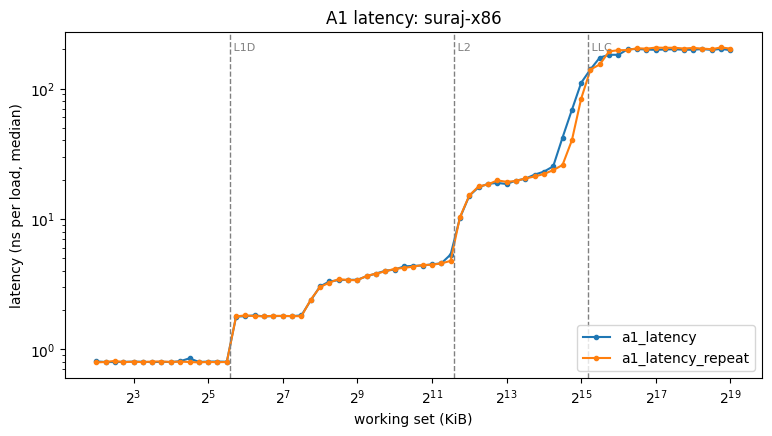

In [5]:
a1 = med[med["benchmark"] == "A1"]
for m in MACHINES:
    sub = a1[a1["machine"] == m]
    if sub.empty:
        print(f"{m}: no A1 data")
        continue
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for sweep, s in sub.groupby("file"):
        s = s.sort_values("size_bytes")
        ax.plot(s["size_bytes"] / 1024, s["median"], marker="o", ms=3, label=sweep)
    for name, b in vendor_sizes(m).items():
        ax.axvline(b / 1024, ls="--", color="gray", lw=1)
        ax.text(b / 1024, 0.97, f" {name}", transform=ax.get_xaxis_transform(),
                va="top", fontsize=8, color="gray")
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("working set (KiB)")
    ax.set_ylabel("latency (ns per load, median)")
    ax.set_title(f"A1 latency: {m}")
    ax.legend()
    save(fig, f"a1_latency_{m}")
    plt.show()

## 3. A1 repeatability

For each size, the spread between the sweeps' medians: (max - min) / min, in percent.
Gate 1 asks for <= 5% (dotted line) on the plateaus; sizes right at a cache boundary
sit on a steep slope and can swing more without that being a failure.
Needs at least two sweeps (`a1_latency.csv`, `a1_latency_repeat.csv`, ...).

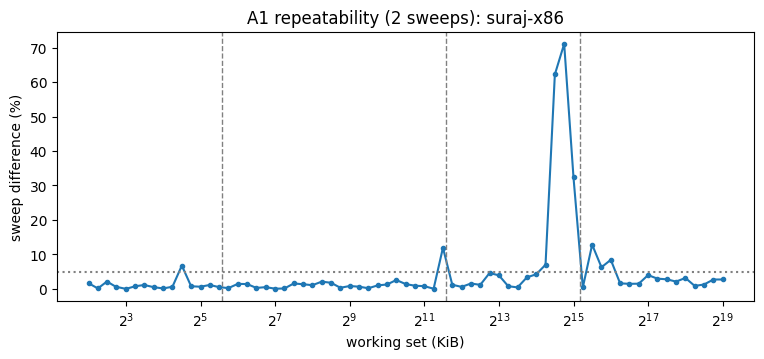

In [6]:
for m in MACHINES:
    sub = a1[a1["machine"] == m]
    wide = sub.pivot_table(index="size_bytes", columns="file", values="median")
    if wide.shape[1] < 2:
        print(f"{m}: needs 2+ A1 sweeps for repeatability")
        continue
    wide = wide.dropna()
    diff = 100 * (wide.max(axis=1) - wide.min(axis=1)) / wide.min(axis=1)
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.plot(diff.index / 1024, diff.values, marker="o", ms=3)
    ax.axhline(5, ls=":", color="gray")
    for name, b in vendor_sizes(m).items():
        ax.axvline(b / 1024, ls="--", color="gray", lw=1)
    ax.set_xscale("log", base=2)
    ax.set_xlabel("working set (KiB)")
    ax.set_ylabel("sweep difference (%)")
    ax.set_title(f"A1 repeatability ({wide.shape[1]} sweeps): {m}")
    save(fig, f"a1_repeatability_{m}")
    plt.show()

## 4. A2 bandwidth

Single-thread DRAM bandwidth per kernel: bar = median of the 5 runs, whisker = min-max.
B, the memory ceiling used by the roofline, is the faster of the `read_sum8` and
`read_sum16` medians (dashed line); why both exist is explained in `bench/bandwidth.c`.
Copy and triad are shown for the report but do not define B.

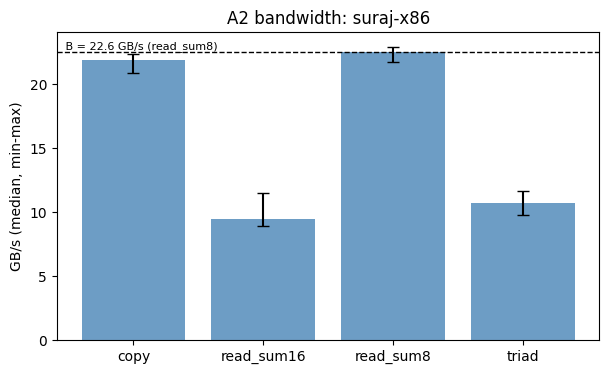

In [7]:
for m in MACHINES:
    sub = med[(med["machine"] == m) & (med["benchmark"] == "A2")].sort_values("kernel")
    if sub.empty:
        print(f"{m}: no A2 data")
        continue
    B, B_kernel, _ = ceilings(m)
    fig, ax = plt.subplots(figsize=(7, 4))
    err = [sub["median"] - sub["min"], sub["max"] - sub["median"]]
    ax.bar(sub["kernel"], sub["median"], yerr=err, capsize=4, color="#6d9dc5")
    if B_kernel:
        ax.axhline(B, ls="--", color="black", lw=1)
        ax.text(0.01, B, f" B = {B:.1f} GB/s ({B_kernel})", transform=ax.get_yaxis_transform(),
                va="bottom", fontsize=8)
    ax.set_ylabel("GB/s (median, min-max)")
    ax.set_title(f"A2 bandwidth: {m}")
    save(fig, f"a2_bandwidth_{m}")
    plt.show()

## 5. B: GEMV and GEMM throughput vs n

FP32 GFLOP/s (median, min-max whiskers) against matrix size n. GEMV does 2 FLOP per
4-byte element it reads, so once the matrix leaves cache it is limited by memory
bandwidth and flattens out. GEMM reuses each element n times, so it climbs towards
the compute peak. The gap between the two curves is the memory wall.

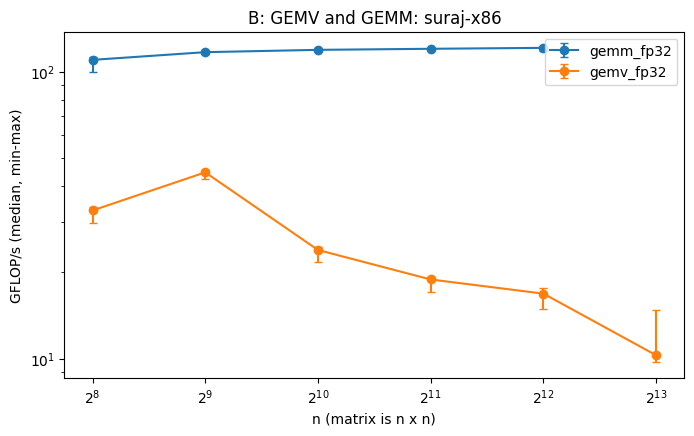

In [8]:
for m in MACHINES:
    sub = med[(med["machine"] == m) & (med["benchmark"] == "B")]
    if sub.empty:
        print(f"{m}: no B data")
        continue
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for kernel, s in sub.groupby("kernel"):
        s = s.sort_values("n")
        ax.errorbar(s["n"], s["median"], yerr=[s["median"] - s["min"], s["max"] - s["median"]],
                    marker="o", capsize=3, label=kernel)
    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("n (matrix is n x n)")
    ax.set_ylabel("GFLOP/s (median, min-max)")
    ax.set_title(f"B: GEMV and GEMM: {m}")
    ax.legend()
    save(fig, f"b_matmul_{m}")
    plt.show()

## 6. Roofline

Attainable throughput = min(P_peak, I x B), log-log, one figure per machine.
I is arithmetic intensity in FLOP per byte of matrix data: GEMV is 2n^2 FLOP over
4n^2 bytes, so I = 0.5 for every n; GEMM is 2n^3 FLOP over 3 x 4n^2 bytes, so I = n/6.
P_peak is the best GEMM median, B the faster read-kernel median. Points under the
slanted part are memory-bound, points under the flat part compute-bound; the corner
(ridge point, P_peak / B) is where one becomes the other. Small-n GEMV can sit above the
roof because its matrix fits in cache and B is a DRAM bandwidth.

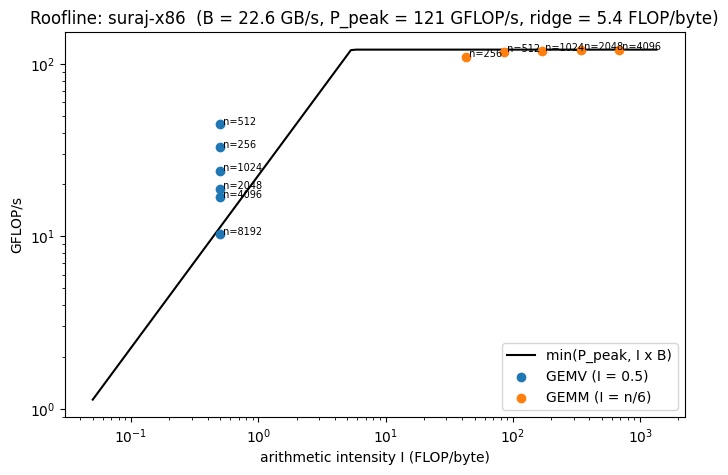

In [9]:
for m in MACHINES:
    B, _, P = ceilings(m)
    sub = med[(med["machine"] == m) & (med["benchmark"] == "B")]
    if pd.isna(B) or pd.isna(P) or sub.empty:
        print(f"{m}: needs A2 and B data for the roofline")
        continue
    gemv = sub[sub["kernel"] == "gemv_fp32"].sort_values("n")
    gemm = sub[sub["kernel"] == "gemm_fp32"].sort_values("n")
    i_max = max(gemm["n"].max() / 6 * 2, 2 * P / B)
    I = [0.05 * 1.1**k for k in range(500) if 0.05 * 1.1**k <= i_max]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(I, [min(P, i * B) for i in I], color="black", lw=1.5, label="min(P_peak, I x B)")
    ax.scatter([0.5] * len(gemv), gemv["median"], label="GEMV (I = 0.5)", zorder=3)
    ax.scatter(gemm["n"] / 6, gemm["median"], label="GEMM (I = n/6)", zorder=3)
    for _, r in gemv.iterrows():
        ax.annotate(f" n={int(r['n'])}", (0.5, r["median"]), fontsize=7)
    for _, r in gemm.iterrows():
        ax.annotate(f" n={int(r['n'])}", (r["n"] / 6, r["median"]), fontsize=7)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("arithmetic intensity I (FLOP/byte)")
    ax.set_ylabel("GFLOP/s")
    ax.set_title(f"Roofline: {m}  (B = {B:.1f} GB/s, P_peak = {P:.0f} GFLOP/s, "
                 f"ridge = {P / B:.1f} FLOP/byte)")
    ax.legend(loc="lower right")
    save(fig, f"roofline_{m}")
    plt.show()

## 7. Verdict

Fixed criteria, decided before looking at the data:

- **H1** (cache steps match the hardware): every detected step, i.e. a size where the
  median latency of the next size is >= 30% higher, divided by the nearest vendor cache
  size (nearest on a log scale), lies within 0.5-2. The step size is the last size
  before the rise, and steps come from the first sweep, as in `analysis/summarize.py`.
- **H2** (GEMV is bandwidth-bound): GEMV / (0.5 x B) lies within 0.75-1.25 for every
  GEMV whose matrix (4n^2 bytes) is larger than `llc_mib`.
- **H3** (the memory wall is large): best GEMM median / GEMV median at the largest
  GEMV n is >= 10.

`n/a` means the data or the `machines.csv` row needed for that test is missing.

In [10]:
def h1(m):
    vs = vendor_sizes(m)
    sweeps = a1[a1["machine"] == m]
    if not vs or sweeps.empty:
        return "n/a", "needs A1 data and vendor sizes"
    first = sweeps[sweeps["file"] == sorted(sweeps["file"].unique())[0]].sort_values("size_bytes")
    sizes, meds = first["size_bytes"].tolist(), first["median"].tolist()
    steps = [s0 for s0, m0, m1 in zip(sizes, meds, meds[1:]) if m1 >= JUMP * m0]
    if not steps:
        return "FAIL", "no step detected"
    parts, ok = [], True
    for s in steps:
        name, v = min(vs.items(), key=lambda kv: abs(math.log(s / kv[1])))
        ratio = s / v
        ok &= H1_RANGE[0] <= ratio <= H1_RANGE[1]
        parts.append(f"{s / 1024:g} KiB/{name}={ratio:.2f}")
    return ("PASS" if ok else "FAIL"), "; ".join(parts)


def h2(m):
    B, _, _ = ceilings(m)
    vs = vendor_sizes(m)
    gemv = med[(med["machine"] == m) & (med["kernel"] == "gemv_fp32")]
    if pd.isna(B) or "LLC" not in vs or gemv.empty:
        return "n/a", "needs A2, GEMV and llc_mib"
    big = gemv[gemv["size_bytes"] > vs["LLC"]].sort_values("n")
    if big.empty:
        return "n/a", "no GEMV matrix larger than the LLC"
    ratios = big["median"] / (0.5 * B)
    ok = ratios.between(*H2_RANGE).all()
    return ("PASS" if ok else "FAIL"), "; ".join(f"n={int(n)}: {r:.2f}" for n, r in zip(big["n"], ratios))


def h3(m):
    _, _, P = ceilings(m)
    gemv = med[(med["machine"] == m) & (med["kernel"] == "gemv_fp32")]
    if pd.isna(P) or gemv.empty:
        return "n/a", "needs GEMM and GEMV"
    last = gemv.loc[gemv["n"].idxmax()]
    ratio = P / last["median"]
    return ("PASS" if ratio >= H3_MIN else "FAIL"), f"{P:.0f} / {last['median']:.1f} (n={int(last['n'])}) = {ratio:.1f}"


rows = []
for m in MACHINES:
    B, B_kernel, P = ceilings(m)
    row = {"machine": m, "B (GB/s)": round(B, 2), "B kernel": B_kernel, "P_peak (GFLOP/s)": round(P, 1)}
    for name, test in (("H1", h1), ("H2", h2), ("H3", h3)):
        row[name], row[f"{name} detail"] = test(m)
    rows.append(row)
verdict = pd.DataFrame(rows).set_index("machine")
with pd.option_context("display.max_colwidth", None):
    display(verdict)

,B (GB/s),B kernel,P_peak (GFLOP/s),H1,H1 detail,H2,H2 detail,H3,H3 detail
machine,,,,,,,,,
suraj-x86,22.56,read_sum8,121.2,FAIL,45.25 KiB/L1D=0.94; 181 KiB/L1D=3.77; 2896.25 KiB/L2=0.94; 3444.25 KiB/L2=1.12; 19483.9 KiB/LLC=0.53; 23170.4 KiB/LLC=0.63; 27554.4 KiB/LLC=0.75,FAIL,n=4096: 1.49; n=8192: 0.91,PASS,121 / 10.3 (n=8192) = 11.8
